# Quality Assessment

In [1]:
import pandas as pd

Load our cleaned DataFrames

In [2]:
# orders_cl.csv
url = "https://drive.google.com/file/d/1QiWLCP_60mpXEYS6A1YEH3S0Whg288xy/view?usp=drive_link"
path = "https://drive.google.com/uc?export=download&id="+url.split("/")[-2]
orders_cl = pd.read_csv(path)

# orderlines_cl.csv
url = "https://drive.google.com/file/d/1hu2Kh3rAOQVC0gGLQN8Zs_HMboVXlu2B/view?usp=drive_link"
path = "https://drive.google.com/uc?export=download&id="+url.split("/")[-2]
orderlines_cl = pd.read_csv(path)

# products_cl.csv
url = "https://drive.google.com/file/d/1IPnKYLSnrST0HBZMeSeNrhFfWU31QvwB/view?usp=drive_link"
path = "https://drive.google.com/uc?export=download&id="+url.split("/")[-2]
products_cl = pd.read_csv(path)

In [3]:
# conversions to datetime

orders_cl['created_date'] = pd.to_datetime(orders_cl['created_date'])
orderlines_cl['date'] = pd.to_datetime(orderlines_cl['date'])

In [4]:
#Removing product_id from orderlines

orderlines_cl = orderlines_cl.drop('product_id', axis=1)

In [5]:
orders_cl.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 226904 entries, 0 to 226903
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   order_id      226904 non-null  int64         
 1   created_date  226904 non-null  datetime64[ns]
 2   total_paid    226904 non-null  float64       
 3   state         226904 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 6.9+ MB


In [6]:
orderlines_cl.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 216250 entries, 0 to 216249
Data columns (total 6 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   id                216250 non-null  int64         
 1   id_order          216250 non-null  int64         
 2   product_quantity  216250 non-null  int64         
 3   sku               216250 non-null  object        
 4   unit_price        216250 non-null  float64       
 5   date              216250 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 9.9+ MB


In [7]:
products_cl.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9992 entries, 0 to 9991
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   sku       9992 non-null   object 
 1   name      9992 non-null   object 
 2   desc      9992 non-null   object 
 3   price     9992 non-null   float64
 4   in_stock  9992 non-null   int64  
 5   type      9946 non-null   object 
dtypes: float64(1), int64(1), object(4)
memory usage: 468.5+ KB


## 1.&nbsp; Define Pandas display format

In [8]:
import pandas as pd
pd.set_option('display.float_format', lambda x: '%.2f' % x)    #Displays floating point numbers to 2 deciimal places only
pd.set_option('display.max_rows', 1000)                        #This displays upto 1000 rows before Pandas starts truncating the output

## 2.&nbsp; Exclude unwanted orders

In [9]:
orderlines_cl['id_order'].nunique()

170213

In [10]:
#To check number of orders in each state

orders_cl['state'].value_counts()

,count
state,
Shopping Basket,117809
Completed,46605
Place Order,40883
Pending,14374
Cancelled,7233


In [11]:
#Discarding orders that were cancelled or are still in shopping basket
#Total number of rows with state COMPLETED: 46605  -------> 180299 rows dropped

orders_cl.loc[~(orders_cl['state']== 'Completed'),:].copy()
orders_mod = orders_cl.loc[orders_cl['state']== 'Completed',:].copy()
orders_mod


,order_id,created_date,total_paid,state
1,241423,2017-11-06 13:10:02,136.15,Completed
2,242832,2017-12-31 17:40:03,15.76,Completed
3,243330,2017-02-16 10:59:38,84.98,Completed
5,245275,2017-06-28 11:35:37,149.00,Completed
6,245595,2017-01-21 12:52:47,112.97,Completed
...,...,...,...,...
226544,527042,2018-03-14 11:47:50,18.98,Completed
226572,527070,2018-03-14 11:50:48,24.97,Completed
226576,527074,2018-03-14 11:51:42,24.97,Completed
226598,527096,2018-03-14 11:58:40,34.96,Completed


In [12]:
orders_mod.info()         #Total num rows: 46605

<class 'pandas.core.frame.DataFrame'>
Index: 46605 entries, 1 to 226614
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   order_id      46605 non-null  int64         
 1   created_date  46605 non-null  datetime64[ns]
 2   total_paid    46605 non-null  float64       
 3   state         46605 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 1.8+ MB


In [13]:
orderlines_cl.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 216250 entries, 0 to 216249
Data columns (total 6 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   id                216250 non-null  int64         
 1   id_order          216250 non-null  int64         
 2   product_quantity  216250 non-null  int64         
 3   sku               216250 non-null  object        
 4   unit_price        216250 non-null  float64       
 5   date              216250 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 9.9+ MB


In [14]:
#List of orders that are NOT present in orderlines
order_list = orderlines_cl['id_order']
orders_mod.loc[~(orders_mod['order_id'].isin(order_list))]


,order_id,created_date,total_paid,state
8,245941,2017-01-01 10:32:23,183.52,Completed
31,257847,2017-11-23 23:46:54,1367.11,Completed
35,258985,2017-07-31 12:52:38,2264.60,Completed
40,259668,2017-10-06 22:06:58,1132.33,Completed
46,262016,2017-08-18 01:05:38,3109.57,Completed
...,...,...,...,...
225860,526357,2018-03-13 12:01:26,1405.99,Completed
225882,526380,2018-03-13 12:16:06,1436.99,Completed
226007,526505,2018-03-13 15:56:14,1421.99,Completed
226009,526507,2018-03-13 16:04:20,1137.97,Completed


In [15]:
#Discarding orders that are not in orderlines (orders –> Keep only orders present in orderlines)
order_list = orderlines_cl['id_order'].unique()
orders_mod = orders_mod.loc[orders_mod['order_id'].isin(order_list),:].copy()      #Total num rows: 79846

In [16]:
orders_mod.info()

<class 'pandas.core.frame.DataFrame'>
Index: 43064 entries, 1 to 226614
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   order_id      43064 non-null  int64         
 1   created_date  43064 non-null  datetime64[ns]
 2   total_paid    43064 non-null  float64       
 3   state         43064 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 1.6+ MB


In [17]:
#List of orders that are NOT present in orders
new_order_list = orders_mod['order_id'].unique()
orderlines_cl.loc[~(orderlines_cl['id_order'].isin(new_order_list)),:]

,id,id_order,product_quantity,sku,unit_price,date
0,1119109,299539,1,OTT0133,18.99,2017-01-01 00:07:19
1,1119110,299540,1,LGE0043,399.00,2017-01-01 00:19:45
2,1119111,299541,1,PAR0071,474.05,2017-01-01 00:20:57
3,1119112,299542,1,WDT0315,68.39,2017-01-01 00:51:40
4,1119113,299543,1,JBL0104,23.74,2017-01-01 01:06:38
...,...,...,...,...,...,...
216245,1650199,527398,1,JBL0122,42.99,2018-03-14 13:57:25
216246,1650200,527399,1,PAC0653,141.58,2018-03-14 13:57:34
216247,1650201,527400,2,APP0698,9.99,2018-03-14 13:57:41
216248,1650202,527388,1,BEZ0204,19.99,2018-03-14 13:58:01


In [18]:
#orderlines –> Keep only orders present in orders

new_order_list = orders_mod['order_id']
orderlines_mod = orderlines_cl.loc[orderlines_cl['id_order'].isin(new_order_list),:].copy()   #Total num rows remaining: 101375

orderlines_mod.info()

<class 'pandas.core.frame.DataFrame'>
Index: 56714 entries, 6 to 215949
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                56714 non-null  int64         
 1   id_order          56714 non-null  int64         
 2   product_quantity  56714 non-null  int64         
 3   sku               56714 non-null  object        
 4   unit_price        56714 non-null  float64       
 5   date              56714 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 3.0+ MB


In [19]:
orders_mod.info()

<class 'pandas.core.frame.DataFrame'>
Index: 43064 entries, 1 to 226614
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   order_id      43064 non-null  int64         
 1   created_date  43064 non-null  datetime64[ns]
 2   total_paid    43064 non-null  float64       
 3   state         43064 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 1.6+ MB


In [20]:
orders_mod.loc[orders_mod['total_paid'] <= 0]

,order_id,created_date,total_paid,state
150,296010,2017-01-09 23:47:00,0.00,Completed
2061,301495,2017-01-03 12:22:02,0.00,Completed


In [21]:
products_cl.loc[products_cl['price'] <= 0]

,sku,name,desc,price,in_stock,type


In [22]:
orderlines_mod.loc[orderlines_mod['unit_price'] <= 0]

,id,id_order,product_quantity,sku,unit_price,date
51711,1236042,349974,1,LIBRO,0.00,2017-04-26 13:48:27
52044,1236769,350328,1,LIBRO,0.00,2017-04-27 13:05:07
52371,1237477,350677,1,LIBRO,0.00,2017-04-28 11:01:30
52638,1238043,349403,1,LIBRO,0.00,2017-04-28 22:49:20
52783,1238358,351091,1,LIBRO,0.00,2017-04-29 16:28:53
60154,1253019,358293,1,LIBRO,0.00,2017-05-23 09:55:21
60156,1253029,358294,1,LIBRO,0.00,2017-05-23 10:03:36
60775,1254410,358899,1,LIBRO,0.00,2017-05-25 01:53:52
61218,1255378,359326,1,LIBRO,0.00,2017-05-26 10:21:15


In [23]:
#Listing all order ids that have erroneous values

orders_to_remove = orderlines_mod.loc[orderlines_mod['unit_price'] <= 0]['id_order'].unique()
orders_to_remove

array([349974, 350328, 350677, 349403, 351091, 358293, 358294, 358899,
       359326])

In [24]:
#The above orders are present in 25 rows which need to be removed

orderlines_mod.loc[orderlines_mod['id_order'].isin(orders_to_remove)]

,id,id_order,product_quantity,sku,unit_price,date
51710,1236041,349974,1,APP0911,985.99,2017-04-26 13:48:27
51711,1236042,349974,1,LIBRO,0.00,2017-04-26 13:48:27
51722,1236068,349974,1,PUR0142,12.99,2017-04-26 14:11:13
51728,1236079,349974,1,MUV0168,12.90,2017-04-26 14:23:15
51731,1236084,349974,1,WAC0234,79.99,2017-04-26 14:28:47
51734,1236088,349974,1,LEX0034,53.99,2017-04-26 14:32:02
52043,1236768,350328,1,APP1581,949.00,2017-04-27 13:05:07
52044,1236769,350328,1,LIBRO,0.00,2017-04-27 13:05:07
52370,1237476,350677,1,APP1581,949.00,2017-04-28 11:01:30
52371,1237477,350677,1,LIBRO,0.00,2017-04-28 11:01:30


In [25]:
orderlines_mod.info()

<class 'pandas.core.frame.DataFrame'>
Index: 56714 entries, 6 to 215949
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                56714 non-null  int64         
 1   id_order          56714 non-null  int64         
 2   product_quantity  56714 non-null  int64         
 3   sku               56714 non-null  object        
 4   unit_price        56714 non-null  float64       
 5   date              56714 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 3.0+ MB


## 3.&nbsp; Exclude orders with unknown products


### 3.1. Analysing SKUs in orderlines & products

In [26]:
products_cl.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9992 entries, 0 to 9991
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   sku       9992 non-null   object 
 1   name      9992 non-null   object 
 2   desc      9992 non-null   object 
 3   price     9992 non-null   float64
 4   in_stock  9992 non-null   int64  
 5   type      9946 non-null   object 
dtypes: float64(1), int64(1), object(4)
memory usage: 468.5+ KB


In [27]:
#List of SKUs from orderlines that are NOT present in products ----> 1394 rows

valid_sku_list = products_cl['sku']
orderlines_mod.loc[(~orderlines_mod['sku'].isin(valid_sku_list)),:]

,id,id_order,product_quantity,sku,unit_price,date
99,1119316,299638,1,SYN0127,223.24,2017-01-01 11:56:18
167,1119477,299706,1,EVU0007,28.49,2017-01-01 13:57:16
173,1119494,299712,1,APP0608,279.99,2017-01-01 14:10:47
303,1119745,299860,1,PAC1516,457.89,2017-01-01 18:40:38
323,1119800,299881,1,SAN0137,49.39,2017-01-01 19:13:45
...,...,...,...,...,...,...
214989,1647363,526037,1,FIB0008,59.99,2018-03-12 16:52:46
214998,1647388,526048,1,SEV0024,59.99,2018-03-12 17:20:40
215056,1647526,526106,1,IFX0020,10.99,2018-03-12 19:09:54
215068,1647561,526122,1,IOT0018,24.99,2018-03-12 20:04:49


In [28]:
products_cl.loc[products_cl['sku']=='PAC1516']

,sku,name,desc,price,in_stock,type


In [29]:
# Valid SKUs that are present in products
valid_sku_list = products_cl['sku']

#Find all id_order that have atleast one unknown SKUs
unknown_sku_order_list = orderlines_mod.loc[~(orderlines_mod['sku'].isin(valid_sku_list)),'id_order'].unique()
unknown_sku_order_list

#Filtering such orders from orderlines
orderlines_mod = orderlines_mod.loc[~(orderlines_mod['id_order'].isin(unknown_sku_order_list))].copy()
orderlines_mod.info()

<class 'pandas.core.frame.DataFrame'>
Index: 54324 entries, 6 to 215949
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                54324 non-null  int64         
 1   id_order          54324 non-null  int64         
 2   product_quantity  54324 non-null  int64         
 3   sku               54324 non-null  object        
 4   unit_price        54324 non-null  float64       
 5   date              54324 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 2.9+ MB


In [30]:
orders_to_keep = orderlines_mod['id_order'].unique()


orders_mod = orders_mod.loc[orders_mod['order_id'].isin(orders_to_keep),:]

In [31]:
orders_mod.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41701 entries, 1 to 226614
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   order_id      41701 non-null  int64         
 1   created_date  41701 non-null  datetime64[ns]
 2   total_paid    41701 non-null  float64       
 3   state         41701 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 1.6+ MB


In [32]:
orderlines_mod.info()

<class 'pandas.core.frame.DataFrame'>
Index: 54324 entries, 6 to 215949
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                54324 non-null  int64         
 1   id_order          54324 non-null  int64         
 2   product_quantity  54324 non-null  int64         
 3   sku               54324 non-null  object        
 4   unit_price        54324 non-null  float64       
 5   date              54324 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 2.9+ MB


In [33]:
products_cl.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9992 entries, 0 to 9991
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   sku       9992 non-null   object 
 1   name      9992 non-null   object 
 2   desc      9992 non-null   object 
 3   price     9992 non-null   float64
 4   in_stock  9992 non-null   int64  
 5   type      9946 non-null   object 
dtypes: float64(1), int64(1), object(4)
memory usage: 468.5+ KB


In [34]:
#Checking if there are any rows with total_paid negative or zero

orders_mod.loc[orders_mod['total_paid'] <= 0]

,order_id,created_date,total_paid,state
150,296010,2017-01-09 23:47:00,0.00,Completed
2061,301495,2017-01-03 12:22:02,0.00,Completed


In [35]:
orders_mod.shape, orderlines_mod.shape

((41701, 4), (54324, 6))

In [36]:
orders_mod['order_id'].nunique(), orderlines_mod['id_order'].nunique()

(41701, 41701)

In [37]:
#Checking if there are any rows with

orderlines_mod.loc[orderlines_mod['unit_price'] <= 0]     #There are 9 rows with unit_price as zero. All rows with these order_ids need to be removed

,id,id_order,product_quantity,sku,unit_price,date


In [38]:
#Listing all order ids that have erroneous values

orders_to_remove = orderlines_mod.loc[orderlines_mod['unit_price'] <= 0]['id_order'].unique()
orders_to_remove

array([], dtype=int64)

In [39]:
#The above orders are present in 25 rows which need to be removed

orderlines_mod.loc[orderlines_mod['id_order'].isin(orders_to_remove)]

,id,id_order,product_quantity,sku,unit_price,date


In [40]:
orders_mod.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41701 entries, 1 to 226614
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   order_id      41701 non-null  int64         
 1   created_date  41701 non-null  datetime64[ns]
 2   total_paid    41701 non-null  float64       
 3   state         41701 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 1.6+ MB


In [41]:
products_cl.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9992 entries, 0 to 9991
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   sku       9992 non-null   object 
 1   name      9992 non-null   object 
 2   desc      9992 non-null   object 
 3   price     9992 non-null   float64
 4   in_stock  9992 non-null   int64  
 5   type      9946 non-null   object 
dtypes: float64(1), int64(1), object(4)
memory usage: 468.5+ KB


In [42]:
orderlines_mod.info()

<class 'pandas.core.frame.DataFrame'>
Index: 54324 entries, 6 to 215949
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                54324 non-null  int64         
 1   id_order          54324 non-null  int64         
 2   product_quantity  54324 non-null  int64         
 3   sku               54324 non-null  object        
 4   unit_price        54324 non-null  float64       
 5   date              54324 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 2.9+ MB


In [43]:
#Removing rows where total_paid <= 0 from orders

orders_with_zero_paid = orders_mod.loc[orders_mod['total_paid'] <= 0,'order_id']

orders_mod = orders_mod.loc[~(orders_mod['order_id'].isin(orders_with_zero_paid)),:]
print(orders_mod.shape)




(41699, 4)


In [44]:
# Keep only orderlines whose 'id_order' exists in cleaned 'orders_mod' table
orderlines_mod = orderlines_mod.loc[orderlines_mod['id_order'].isin(orders_mod['order_id'])]

# Verify that they match now
print("Unique orders in orders_mod:", orders_mod['order_id'].nunique())
print("Unique orders in orderlines_mod:", orderlines_mod['id_order'].nunique())

Unique orders in orders_mod: 41699
Unique orders in orderlines_mod: 41699


In [45]:
orders_mod.shape, orderlines_mod.shape, products_cl.shape

((41699, 4), (54322, 6), (9992, 6))

## 4.&nbsp; Explore the revenue from different tables

In [46]:
orders_s4 = orders_mod.copy()
orderlines_s4 = orderlines_mod.copy()
products_s4 = products_cl.copy()

#### Step 1:
Create the `unit_price_total` as `orderlines.unit_price` * `orderlines.product_quantity`

In [47]:
# your code here

# create a new column in the orderlines table and store the product of the unit price and quantity

orderlines_s4['unit_price_total'] = orderlines_s4['unit_price'] * orderlines_s4['product_quantity'] # these are total earnings from a given product in a given order

#### Step 2:
Group by `id_order`, summarising by the sum of `unit_price_total`

In [48]:
# your code here
# aggregate (sum) the total price of all products sold over the column id_order

orderlines_total_price = orderlines_s4.groupby('id_order').agg(total_price=('unit_price_total', 'sum'))
orderlines_total_price

,total_price
id_order,
241423,129.16
242832,10.77
243330,77.99
245275,149.00
245595,105.98
...,...
527042,13.99
527070,19.98
527074,19.98


### What is the average difference between `total_paid` and `unit_price_total`?

In [49]:
# your code here
# Merge the orders table with the grouped orderlines total
# extract the data of interest - total_paid column from orders table

orders_total_paid = orders_s4[['order_id', 'total_paid']].set_index('order_id')
orders_total_paid

,total_paid
order_id,
241423,136.15
242832,15.76
243330,84.98
245275,149.00
245595,112.97
...,...
527042,18.98
527070,24.97
527074,24.97


In [50]:
# the difference between total_paid (orders) and total_price (orderlines aggregate)

diff_df = orders_total_paid['total_paid'].sub(orderlines_total_price['total_price']).reset_index(name='difference')
diff_df

,order_id,difference
0,241423,6.99
1,242832,4.99
2,243330,6.99
3,245275,0.00
4,245595,6.99
...,...,...
41694,527042,4.99
41695,527070,4.99
41696,527074,4.99
41697,527096,4.99


In [51]:
# check the statistics of the requested difference

diff_df['difference'].describe() # average difference is 4.48

,difference
count,41699.00
mean,4.48
std,26.05
min,-165.00
25%,0.00
50%,4.99
75%,6.99
max,3984.99


### What is the distribution of these differences?

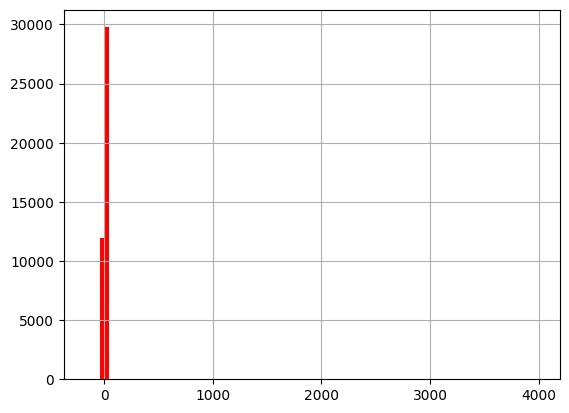

In [52]:
# visualize the distribution of differences with a histogram

diff_df['difference'].hist(bins=100, color='red');

# most diffferences are clustered around the 0 - more than 40000 values are around 0

### Can all the differences be explained by shipping costs? If not, what are other plausible explanations?

In [53]:
# your explanation here
# observe the basic statistics

diff_df['difference'].describe()

# the quartiles correspond to values realistic for shipping cost

# maximum and minimum are confusing - it is unclear what could be the cause for such extreme values

# perhaps there was a mistake in recording the prices

,difference
count,41699.00
mean,4.48
std,26.05
min,-165.00
25%,0.00
50%,4.99
75%,6.99
max,3984.99


### If there are differences that you can’t explain: what should you do with these orders?

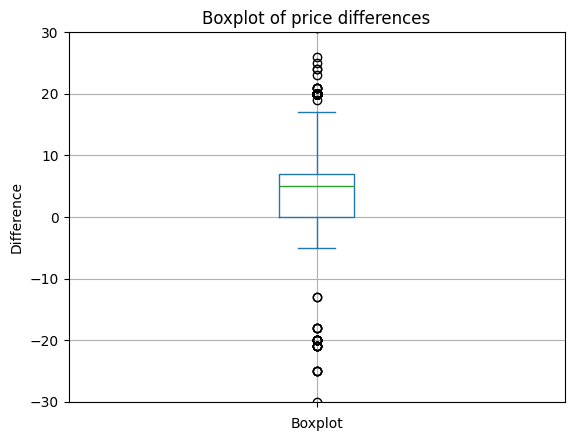

In [54]:
# your code here
# let's first visualize the boxplot of differences

import matplotlib.pyplot as plt

ax = diff_df['difference'].plot.box()
ax.set_ylim(-30, 30)
ax.grid()

ax.set_xticklabels([]) # removes the automatic labeling of the x axis

plt.title('Boxplot of price differences') # set title
plt.xlabel('Boxplot')                     # set x label
plt.ylabel('Difference')                  # set y label

plt.show()

# we can get rid of the outliers and remove the orders that correspond to them

### Removal of the outliers and corresponding orders

In [55]:
# to detect the outliers, we first have to find the upper and lower whisker values, and then the interquartile range (IQR)

# we can read the main quartiles from the .describe() method's output

q1 = 0
q2 = 4.99
q3 = 6.99

# or we can call appropriate methods

q1 = diff_df['difference'].quantile(0.25)
q2 = diff_df['difference'].quantile(0.5)
q3 = diff_df['difference'].quantile(0.75)

# calculate the relevant boundaries

iqr = q3 - q1                  # calculate the interquartile range (IQR)
lower_whisker = q1 - 1.5 * iqr # find the value of the lower whisker
upper_whisker = q3 + 1.5 * iqr # find the value of the upper whisker

# we will remove orders related to differences that fall outside of the whiskers

In [56]:
# create a mask for differences outside of the whiskers

extreme_differences_mask = (diff_df['difference'] < lower_whisker) | (diff_df['difference'] > upper_whisker)
num_outliers = extreme_differences_mask.sum()
num_outliers

# we discover that there are 714 outliers, which is acceptable, given that we are considering more than 40000 orders

np.int64(714)

In [57]:
# apply the mask

sensible_orders = diff_df.loc[~extreme_differences_mask, 'order_id'] # extract the orders to be kept

orders_s4 = orders_s4.loc[orders_s4['order_id'].isin(sensible_orders), :]             # perform the filtering of orders table
orderlines_s4 = orderlines_s4.loc[orderlines_s4['id_order'].isin(sensible_orders), :] # perform the filtering of orderlines table

# we kept only those orders for which the difference between total_paid and unit_price_total_paid is realistically small

orders_s4['order_id'].nunique(), orderlines_s4['id_order'].nunique()

(40985, 40985)

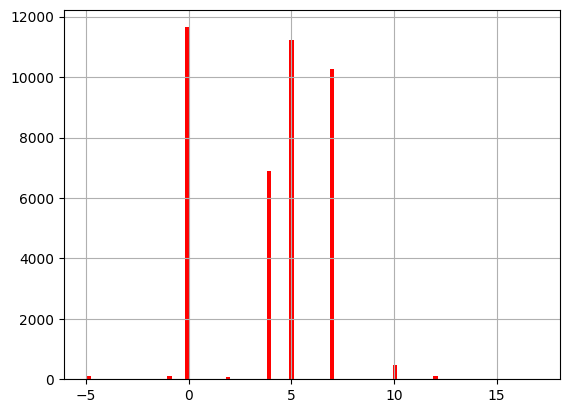

In [58]:
# visualize the differences in total paid price when the outliers are gone

diff_df.loc[~extreme_differences_mask, 'difference'].hist(bins=100, color='red');

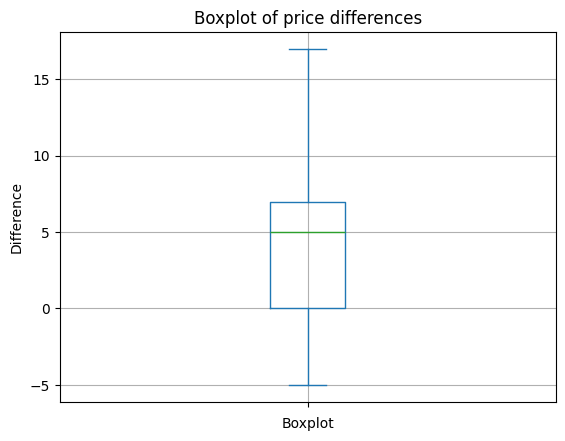

In [59]:
# visualize the differences boxplot after the outliers have been removed

ax = diff_df.loc[~extreme_differences_mask, 'difference'].plot.box()

ax.grid()
ax.set_xticklabels([]) # removes the automatic labeling of the x axis

plt.title('Boxplot of price differences') # title
plt.xlabel('Boxplot')                     # x label
plt.ylabel('Difference')                  # y label

plt.show()

##Revenue Generation Analysis

In [60]:
orders_s4.info()

<class 'pandas.core.frame.DataFrame'>
Index: 40985 entries, 1 to 226614
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   order_id      40985 non-null  int64         
 1   created_date  40985 non-null  datetime64[ns]
 2   total_paid    40985 non-null  float64       
 3   state         40985 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 1.6+ MB


In [61]:
orderlines_s4.info()

<class 'pandas.core.frame.DataFrame'>
Index: 53231 entries, 6 to 215949
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                53231 non-null  int64         
 1   id_order          53231 non-null  int64         
 2   product_quantity  53231 non-null  int64         
 3   sku               53231 non-null  object        
 4   unit_price        53231 non-null  float64       
 5   date              53231 non-null  datetime64[ns]
 6   unit_price_total  53231 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(3), object(1)
memory usage: 3.2+ MB


In [62]:
products_s4.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9992 entries, 0 to 9991
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   sku       9992 non-null   object 
 1   name      9992 non-null   object 
 2   desc      9992 non-null   object 
 3   price     9992 non-null   float64
 4   in_stock  9992 non-null   int64  
 5   type      9946 non-null   object 
dtypes: float64(1), int64(1), object(4)
memory usage: 468.5+ KB


In [63]:
#Total Revenue Generated
total_revenue = orderlines_s4['unit_price_total'].sum()
rounded_revenue = round(total_revenue, 2)

print("Total Revenue: €", rounded_revenue)

Total Revenue: € 7817204.4


##Business Questions

####How many products are being discounted?

In [64]:
# Merged orderlines_s4 with products_s4 on 'sku' to compare selling price vs catalog price
merged_products = orderlines_s4.merge(products_s4, on='sku', suffixes=('_order', '_catalog'))

# A product is discounted if its unit_price is less than its catalog price
discounted_mask = merged_products['unit_price'] < merged_products['price']

# Count unique products (SKUs) that have been sold at a discount at least once
num_discounted_products = merged_products.loc[discounted_mask, 'sku'].nunique()

print(f"Number of unique products being discounted: {num_discounted_products}")     #4906

# Optional: View a breakdown of the discounted products and how often they were discounted
discounted_summary = merged_products.loc[discounted_mask, ['sku', 'name', 'unit_price', 'price']].drop_duplicates()
display(discounted_summary.head(10))

Number of unique products being discounted: 4906


,sku,name,unit_price,price
0,OWC0100,OWC In-line Digital Temperature Sensor Kit HDD...,47.49,60.99
1,IOT0014,iOttie Easy View 2 Car Black Support,18.99,22.95
2,APP0700,Apple 85W MagSafe 2 charger MacBook Pro screen...,72.19,89.00
3,CRU0039-A,(Open) Crucial 240GB SSD 7mm BX200,60.90,76.99
4,PEB0015,Pebble Smartwatch Time Steel Black,142.49,299.99
5,BEA0065,Solo3 Beats Headphones Wireless On-Ear Rose Gold,256.49,299.95
6,SAT0010,Satechi Aluminum Silver Mouse,18.99,29.99
7,SYN0139,Synology DS216j NAS Server Mac and PC,166.24,175.99
8,LOG0191,Ultimate Ears Boom 2 Bluetooth Portable Speake...,142.49,209.00
9,LGE0031-A,"Open - LG Monitor 24 ""W 5ms HDMI 24MP58VQ-White",127.08,159.00


####How big are the offered discounts as a percentage of the product prices?

On Average Discounted products are sold 23.24 times more

In [65]:
# Filter for rows where a discount occurred (selling price < catalog price)
discounted_df = merged_products[merged_products['unit_price'] < merged_products['price']].copy()

# Calculate the discount percentage for each discounted order line
discounted_df['discount_percentage'] = ((discounted_df['price'] - discounted_df['unit_price']) / discounted_df['price']) * 100

# View summary statistics of the discount percentages (mean, min, max, quartiles)
print("Discount Percentage Summary Statistics:")
print(discounted_df['discount_percentage'].describe())

# Optional: View a preview table showing the SKU, name, standard price, selling price, and discount %
summary_columns = ['sku', 'name', 'price', 'unit_price', 'discount_percentage']
display(discounted_df[summary_columns].head(10))

Discount Percentage Summary Statistics:
count   49404.00
mean       23.24
std        17.33
min         0.00
25%        11.11
50%        19.54
75%        29.97
max        97.14
Name: discount_percentage, dtype: float64


,sku,name,price,unit_price,discount_percentage
0,OWC0100,OWC In-line Digital Temperature Sensor Kit HDD...,60.99,47.49,22.13
1,IOT0014,iOttie Easy View 2 Car Black Support,22.95,18.99,17.25
2,APP0700,Apple 85W MagSafe 2 charger MacBook Pro screen...,89.00,72.19,18.89
3,CRU0039-A,(Open) Crucial 240GB SSD 7mm BX200,76.99,60.90,20.90
4,PEB0015,Pebble Smartwatch Time Steel Black,299.99,142.49,52.50
5,BEA0065,Solo3 Beats Headphones Wireless On-Ear Rose Gold,299.95,256.49,14.49
6,SAT0010,Satechi Aluminum Silver Mouse,29.99,18.99,36.68
7,SYN0139,Synology DS216j NAS Server Mac and PC,175.99,166.24,5.54
8,LOG0191,Ultimate Ears Boom 2 Bluetooth Portable Speake...,209.00,142.49,31.82
9,LGE0031-A,"Open - LG Monitor 24 ""W 5ms HDMI 24MP58VQ-White",159.00,127.08,20.08


## Discount Buckets & Revenue analysis

####Merging Datasets

In [66]:
#Merging the Datasets
#Merging orders & orderlines

orderlines_order = orderlines_s4.merge(orders_s4, left_on='id_order', right_on='order_id',suffixes=('_ol', '_order'))
orderlines_order.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53231 entries, 0 to 53230
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                53231 non-null  int64         
 1   id_order          53231 non-null  int64         
 2   product_quantity  53231 non-null  int64         
 3   sku               53231 non-null  object        
 4   unit_price        53231 non-null  float64       
 5   date              53231 non-null  datetime64[ns]
 6   unit_price_total  53231 non-null  float64       
 7   order_id          53231 non-null  int64         
 8   created_date      53231 non-null  datetime64[ns]
 9   total_paid        53231 non-null  float64       
 10  state             53231 non-null  object        
dtypes: datetime64[ns](2), float64(3), int64(4), object(2)
memory usage: 4.5+ MB


In [67]:
#Merging the merged table with products
merged_datasets = orderlines_order.merge(products_s4,on='sku',how='left', suffixes=('','_prod'))
merged_datasets.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53231 entries, 0 to 53230
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                53231 non-null  int64         
 1   id_order          53231 non-null  int64         
 2   product_quantity  53231 non-null  int64         
 3   sku               53231 non-null  object        
 4   unit_price        53231 non-null  float64       
 5   date              53231 non-null  datetime64[ns]
 6   unit_price_total  53231 non-null  float64       
 7   order_id          53231 non-null  int64         
 8   created_date      53231 non-null  datetime64[ns]
 9   total_paid        53231 non-null  float64       
 10  state             53231 non-null  object        
 11  name              53231 non-null  object        
 12  desc              53231 non-null  object        
 13  price             53231 non-null  float64       
 14  in_stock          5323

####Discount percentage calculation

In [68]:
# Calculate the discount percentage for each row
merged_datasets['discount_pct'] = (
    (merged_datasets['price'] - merged_datasets['unit_price']) / merged_datasets['price']) * 100


merged_datasets[['sku', 'name', 'price', 'unit_price', 'discount_pct']].head(10)

,sku,name,price,unit_price,discount_pct
0,OWC0100,OWC In-line Digital Temperature Sensor Kit HDD...,60.99,47.49,22.13
1,IOT0014,iOttie Easy View 2 Car Black Support,22.95,18.99,17.25
2,APP0700,Apple 85W MagSafe 2 charger MacBook Pro screen...,89.00,72.19,18.89
3,CRU0039-A,(Open) Crucial 240GB SSD 7mm BX200,76.99,60.90,20.90
4,PEB0015,Pebble Smartwatch Time Steel Black,299.99,142.49,52.50
5,BEA0065,Solo3 Beats Headphones Wireless On-Ear Rose Gold,299.95,256.49,14.49
6,SAT0010,Satechi Aluminum Silver Mouse,29.99,18.99,36.68
7,SYN0139,Synology DS216j NAS Server Mac and PC,175.99,166.24,5.54
8,LOG0191,Ultimate Ears Boom 2 Bluetooth Portable Speake...,209.00,142.49,31.82
9,LGE0031-A,"Open - LG Monitor 24 ""W 5ms HDMI 24MP58VQ-White",159.00,127.08,20.08


In [69]:
merged_datasets['discount_pct'].isnull().sum()

np.int64(0)

In [70]:
merged_datasets.shape

(53231, 17)

In [71]:
#Assigning markups - where unit_price is higher than catalog price
markups = merged_datasets.loc[merged_datasets['discount_pct'] <= 0,:]
len(markups)                                                         #Num rows with pct <= 0: 3827

3827

In [72]:
#Percentage of markups(Unit price higher or equal to catalog price)

(len(markups)/len(merged_datasets)) * 100

7.189419699047547

####Discount buckets creation

In [73]:
#Creating discount buckets

import numpy as np

#Using np.select for this. It's like CASE WHEN in SQL.
#Each row is checked against the condition & assigned respective value.
#When no match is found, default value is assigned.

# Define conditions for markups, full price, and each discount tier
conditions = [
    merged_datasets['discount_pct'] < 0,                                       # Markup (unit price > list price)
    merged_datasets['discount_pct'] == 0,                                                # Full Price (0%)
    (merged_datasets['discount_pct'] > 0) & (merged_datasets['discount_pct'] <= 10),     # 1–10% discount
    (merged_datasets['discount_pct'] > 10) & (merged_datasets['discount_pct'] <= 25),    # 10–25% discount
    (merged_datasets['discount_pct'] > 25) & (merged_datasets['discount_pct'] <= 50),    # 25–50% discount
    merged_datasets['discount_pct'] > 50                                                 # 50%+ discount
]

choices = [
    'Markup (< 0%)',
    'Full Price (0%)',
    '1–10%',
    '10–25%',
    '25–50%',
    '50%+'
]

# Apply the conditions to create the bucket column
merged_datasets['discount_bucket'] = np.select(conditions, choices, default='Unknown')

# Preview the bucket counts to verify the distribution
print(merged_datasets['discount_bucket'].value_counts())

discount_bucket
10–25%             21765
25–50%             12158
1–10%              10506
50%+                4975
Full Price (0%)     2256
Markup (< 0%)       1571
Name: count, dtype: int64


####Revenue summary per discount bucket

In [74]:
# --- Final Step: Aggregate Revenue and Units Sold by Discount Bucket ---

#observed=False: Pandas will show all pre-defined categories in list, even if a specific bucket has 0 transactions.
revenue_summary = merged_datasets.groupby('discount_bucket', observed=False).agg(
    total_revenue=('unit_price_total', 'sum'),       # Total revenue generated per bucket
    total_units_sold=('product_quantity', 'sum'),    # Total quantity of items sold per bucket
    total_transactions=('id_order', 'count')         # Number of transaction lines per bucket
).reset_index()


# Calculate the percentage share of overall revenue for each bucket
total_overall_revenue = revenue_summary['total_revenue'].sum()
revenue_summary['revenue_share_pct'] = (revenue_summary['total_revenue'] / total_overall_revenue) * 100

# Round numerical columns for clean presentation
revenue_summary['total_revenue'] = revenue_summary['total_revenue'].round(2)
revenue_summary['revenue_share_pct'] = revenue_summary['revenue_share_pct'].round(2)

# Display the final summary table
display(revenue_summary)

,discount_bucket,total_revenue,total_units_sold,total_transactions,revenue_share_pct
0,10–25%,3471643.32,24707,21765,44.41
1,1–10%,2647204.05,11693,10506,33.86
2,25–50%,973516.85,13486,12158,12.45
3,50%+,149759.20,5784,4975,1.92
4,Full Price (0%),241598.04,2561,2256,3.09
5,Markup (< 0%),333482.94,1780,1571,4.27


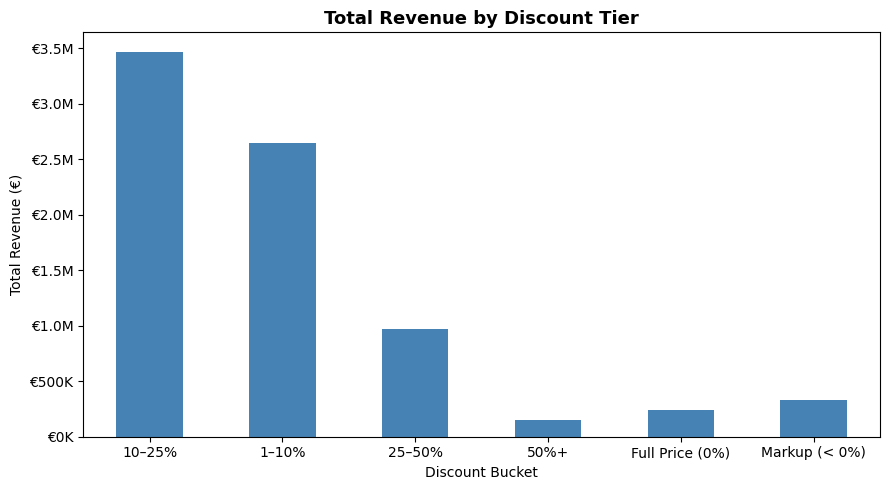

In [75]:
#Plot for Revenue pere Discount bucket

import matplotlib.pyplot as plt

# Create the bar plot using the table from Step 1
ax = revenue_summary.plot(kind='bar', x='discount_bucket', y='total_revenue', legend=False, figsize=(9, 5), color='steelblue')

# Titles and axis labels
plt.title('Total Revenue by Discount Tier', fontsize=13, fontweight='bold')
plt.xlabel('Discount Bucket')
plt.ylabel('Total Revenue (€)')

# Format y-axis dynamically (M for millions, K for thousands)
ax.yaxis.set_major_formatter(lambda x, pos: f'€{x*1e-6:,.1f}M' if x >= 1e6 else f'€{x*1e-3:,.0f}K')

# Keep x-axis labels horizontal
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

/tmp/ipykernel_3133/2879688651.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f'€{val*1e-6:.1f}M' for val in current_ticks], fontsize=10)


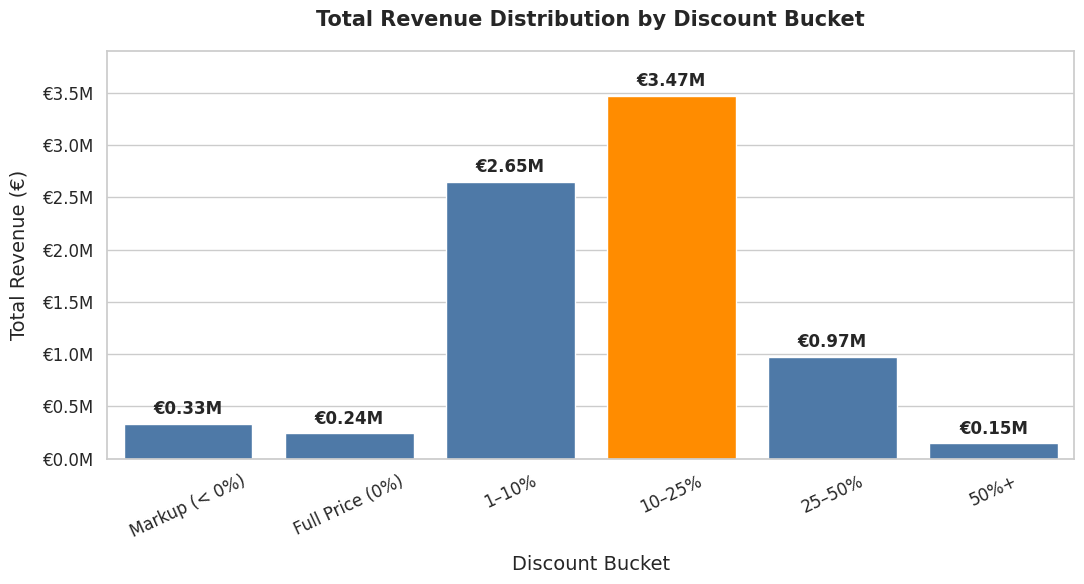

In [76]:
#FINAL PLOT to display Total Revenue Distribution by Discount Bucket

import matplotlib.pyplot as plt
import seaborn as sns

# Define the logical order of discount buckets from lowest to highest discount depth
bucket_order = [
    'Markup (< 0%)',
    'Full Price (0%)',
    '1–10%',
    '10–25%',
    '25–50%',
    '50%+',
]

# Set up the plot size and style
plt.figure(figsize=(11, 6))
sns.set_theme(style='whitegrid')

# Define custom colors
COLOR_STEEL_BLUE = '#4E79A7'  # Remaining bars
COLOR_TANGERINE = '#FF8C00'  # Highest bar

# Create the bar chart (using a placeholder color first)
ax = sns.barplot(
    data=revenue_summary,
    x='discount_bucket',
    y='total_revenue',
    order=bucket_order,
    color=COLOR_STEEL_BLUE,
)

# Dynamically find the tallest bar and color it Tangerine, others Steel Blue
max_height = max(p.get_height() for p in ax.patches)
for p in ax.patches:
  if p.get_height() == max_height:
    p.set_facecolor(COLOR_TANGERINE)
  else:
    p.set_facecolor(COLOR_STEEL_BLUE)

# Add title and labels optimized for a presentation
plt.title(
    'Total Revenue Distribution by Discount Bucket',
    fontsize=15,
    fontweight='bold',
    pad=18,
)
plt.xlabel('Discount Bucket', fontsize=14, labelpad=10)
plt.ylabel('Total Revenue (€)', fontsize=14, labelpad=10)
plt.xticks(rotation=25, fontsize=12)

# Format y-axis in Millions (€M) for cleaner executive readability
current_ticks = plt.yticks()[0]
ax.set_yticklabels([f'€{val*1e-6:.1f}M' for val in current_ticks], fontsize=10)
# Clean Y-axis formatting without the warning
ax.set_yticks([0e6, 0.5e6, 1.0e6, 1.5e6, 2.0e6, 2.5e6, 3.0e6, 3.5e6])
ax.set_yticklabels(
    ['€0.0M', '€0.5M', '€1.0M', '€1.5M', '€2.0M', '€2.5M', '€3.0M', '€3.5M'],
    fontsize=12,
)
ax.set_ylim(0, 3.9e6)

# Add data labels on top of each bar (showing Euros in millions)
for p in ax.patches:
  height = p.get_height()
  if height > 0:  # Avoid labeling empty bars if any
    ax.annotate(
        f'€{height*1e-6:.2f}M',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        xytext=(0, 4),
        textcoords='offset points',
        fontsize=12,
        fontweight='semibold',
    )

plt.tight_layout()

#Saving the file in .svg format
plt.savefig(
    'total_revenue_distribution_by_discount_bucket.svg',
    format='svg',
    bbox_inches='tight',  # Ensures labels, titles, and ticks are never cut off
    transparent=True,
)

plt.show()

In [77]:
#Uncomment this when the .svg file needs to be downloaded on local system
#Importing & downloading the .svg file

#import os
#print([f for f in os.listdir() if f.endswith('.svg')])

#from google.colab import files
#files.download('total_revenue_distribution_by_discount_bucket.svg')

## 6.&nbsp; 🧩 Keep asking questions(LMS)

In [78]:
# 1. What is the time period that the dataset covers?

min_date = orders_s4['created_date'].min()
max_date = orders_s4['created_date'].max()
print(f"Time Period: From {min_date.strftime('%Y-%m-%d')} to {max_date.strftime('%Y-%m-%d')}")

Time Period: From 2017-01-01 to 2018-03-14


In [79]:
# 2. What is the overall revenue for that time?

overall_revenue = merged_datasets['unit_price_total'].sum().round(2)
print(f"Overall Revenue: €{overall_revenue}")

Overall Revenue: €7817204.4


In [80]:
#Are there seasonal patterns in the evolution of sales? (Monthly aggregated sales)

monthly_sales = (merged_datasets.set_index('created_date')
.resample('ME')['unit_price_total'].sum().round(2)).reset_index()

monthly_sales

,created_date,unit_price_total
0,2017-01-31,604091.87
1,2017-02-28,332612.30
2,2017-03-31,24856.02
3,2017-04-30,228090.63
4,2017-05-31,331214.98
5,2017-06-30,286575.67
6,2017-07-31,599404.93
7,2017-08-31,379560.32
8,2017-09-30,387942.85
9,2017-10-31,547599.55


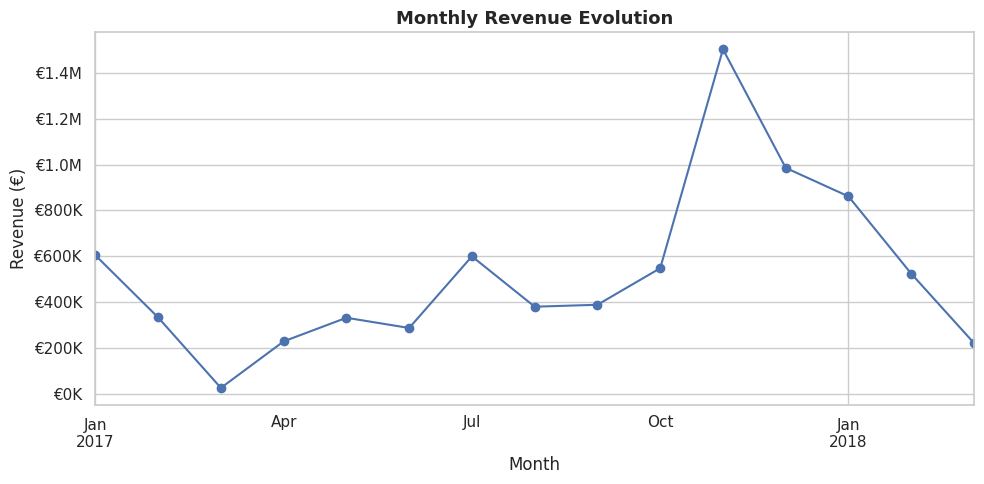

In [81]:
import matplotlib.pyplot as plt

# 1. Plot the monthly sales directly
ax = monthly_sales.plot(x='created_date', y='unit_price_total', kind='line', marker='o', legend=False, figsize=(10, 5))

# 2. Add titles and labels
plt.title('Monthly Revenue Evolution', fontsize=13, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Revenue (€)')

# 3. Format y-axis in K/M
ax.yaxis.set_major_formatter(lambda x, pos: f'€{x*1e-6:,.1f}M' if x >= 1e6 else f'€{x*1e-3:,.0f}K')

plt.tight_layout()
plt.show()

In [82]:
merged_datasets.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53231 entries, 0 to 53230
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                53231 non-null  int64         
 1   id_order          53231 non-null  int64         
 2   product_quantity  53231 non-null  int64         
 3   sku               53231 non-null  object        
 4   unit_price        53231 non-null  float64       
 5   date              53231 non-null  datetime64[ns]
 6   unit_price_total  53231 non-null  float64       
 7   order_id          53231 non-null  int64         
 8   created_date      53231 non-null  datetime64[ns]
 9   total_paid        53231 non-null  float64       
 10  state             53231 non-null  object        
 11  name              53231 non-null  object        
 12  desc              53231 non-null  object        
 13  price             53231 non-null  float64       
 14  in_stock          5323

In [83]:
# 4. What are the most sold products (by quantity)?

top_products_qty = (
    merged_datasets.groupby(['sku', 'name'])['product_quantity']
    .sum()
    .reset_index()
    .sort_values(by='product_quantity', ascending=False)
    .head(5)
)

top_products_qty

,sku,name,product_quantity
448,APP1190,IPhone AppleCare Protection Plan,955
360,APP0698,Apple Lightning Cable Connector to USB 1m Whit...,820
655,APP1922,AirPods Apple Bluetooth Headset for iPhone iPa...,537
378,APP0927,EarPods Apple Headphones with Remote and Mic (...,489
4906,WDT0183,"Red 4TB WD 35 ""Mac PC hard drive and NAS",476


In [84]:
# 5. What are the products that generate the most revenue?

top_products_rev = (
    merged_datasets.groupby(['sku', 'name'])['unit_price_total']
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

top_products_rev

,,unit_price_total
sku,name,
LGE0044,"LG 27UD88-W Monitor 27 ""UHD 4K USB 3.0 USB-C",135375.83
APP2446,Apple iPhone 6 32GB Space Gray,104560.64
APP1922,AirPods Apple Bluetooth Headset for iPhone iPad iPod and Apple Watch,86473.26
APP2477,Apple iPhone 64GB Space Gray 8,85301.93
APP1970,Apple iPhone 32GB Space Gray,80715.76


## 7.&nbsp; 🧩 Analyze discounts(LMS)
Used Discount pct instead of creating a new column for Discount


In [85]:
#Grouping my Month to introduce time dimension


monthly_avg_discount = (
    merged_datasets.set_index('created_date')
    .resample('ME')['discount_pct']
    .mean()
    .rename('discount_pct_avg')
.reset_index()
)

display(monthly_avg_discount)

,created_date,discount_pct_avg
0,2017-01-31,24.87
1,2017-02-28,19.54
2,2017-03-31,19.05
3,2017-04-30,18.26
4,2017-05-31,15.40
5,2017-06-30,17.16
6,2017-07-31,24.98
7,2017-08-31,20.49
8,2017-09-30,20.02
9,2017-10-31,22.05


In [86]:
#Merging the data to get revenue included
monthly_df = monthly_avg_discount.merge(monthly_sales, on='created_date',how = 'inner')

#Renaming unit_price_total to monthly_revenue
monthly_df = monthly_df.rename(
    columns={'unit_price_total': 'monthly_revenue'}
)

monthly_df

,created_date,discount_pct_avg,monthly_revenue
0,2017-01-31,24.87,604091.87
1,2017-02-28,19.54,332612.30
2,2017-03-31,19.05,24856.02
3,2017-04-30,18.26,228090.63
4,2017-05-31,15.40,331214.98
5,2017-06-30,17.16,286575.67
6,2017-07-31,24.98,599404.93
7,2017-08-31,20.49,379560.32
8,2017-09-30,20.02,387942.85
9,2017-10-31,22.05,547599.55


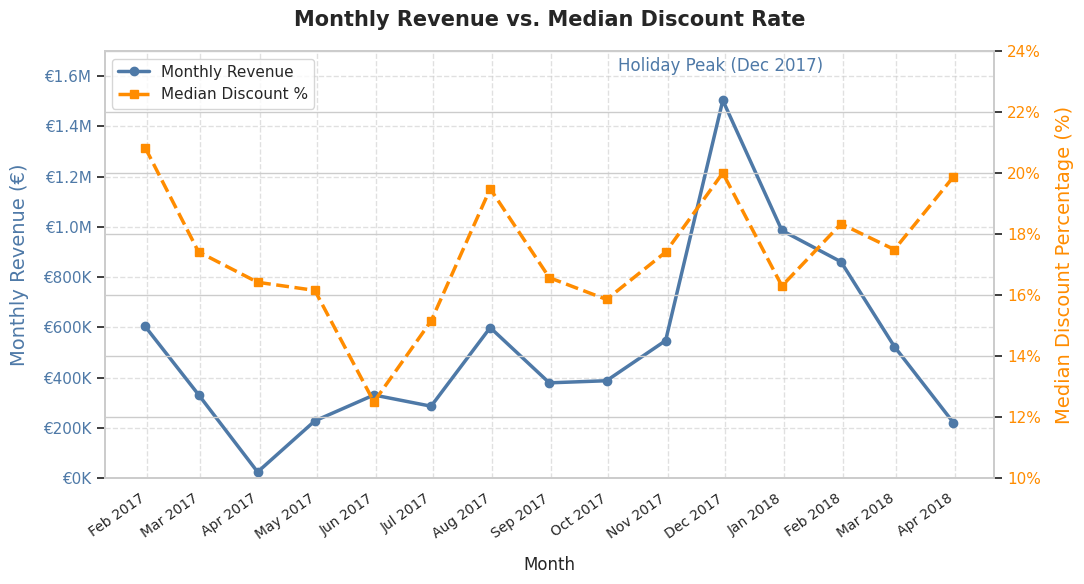

In [87]:
#Plot in Backup slides in final presentation deck
#FINAL PLOT for Monthly Revenue & Discount Percentage (Median)

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import pandas as pd
import seaborn as sns

# 1. Monthly Aggregation
discount_col = 'discount_pct'  # Update if your discount column has a different name
monthly_df = (
    merged_datasets.groupby(pd.Grouper(key='created_date', freq='ME'))
    .agg(
        monthly_revenue=('unit_price_total', 'sum'),
        median_discount=(discount_col, 'median'),
    )
    .reset_index()
)

# 2. Figure Setup & Styling
fig, ax1 = plt.subplots(figsize=(11, 6))
sns.set_theme(style='whitegrid')

COLOR_STEEL_BLUE = '#4E79A7'  # Muted Steel Blue (Revenue)
COLOR_TANGERINE = '#FF8C00'  # Bright Tangerine (Median Discount)

# 3. Primary Axis: Monthly Revenue (Left)
ax1.set_xlabel('Month', fontsize=12, labelpad=10)
ax1.set_ylabel(
    'Monthly Revenue (€)', color=COLOR_STEEL_BLUE, fontsize=14, labelpad=10
)
line1 = ax1.plot(
    monthly_df['created_date'],
    monthly_df['monthly_revenue'],
    color=COLOR_STEEL_BLUE,
    marker='o',
    linewidth=2.5,
    label='Monthly Revenue',
)
ax1.tick_params(axis='y', labelcolor=COLOR_STEEL_BLUE)
ax1.yaxis.set_major_formatter(
    FuncFormatter(
        lambda x, _: f'€{x*1e-6:.1f}M' if x >= 1e6 else f'€{x*1e-3:.0f}K'
    )
)
ax1.set_ylim(0, 1.7e6)

# 4. Secondary Axis: Median Discount (Right)
ax2 = ax1.twinx()
ax2.set_ylabel(
    'Median Discount Percentage (%)',
    color=COLOR_TANGERINE,
    fontsize=14,
    labelpad=10,
)
line2 = ax2.plot(
    monthly_df['created_date'],
    monthly_df['median_discount'],
    color=COLOR_TANGERINE,
    marker='s',
    linewidth=2.5,
    linestyle='--',
    label='Median Discount %',
)
ax2.tick_params(axis='y', labelcolor=COLOR_TANGERINE)
ax2.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:.0f}%'))
ax2.set_ylim(10, 24)

# 5. X-Axis Formatting & Rotation
ax1.xaxis.set_major_locator(mdates.MonthLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.setp(ax1.get_xticklabels(), rotation=35, ha='right', fontsize=10)

# 6. Legend, Title & Grid
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', frameon=True, fontsize=11)

plt.title(
    'Monthly Revenue vs. Median Discount Rate',
    fontsize=15,
    fontweight='bold',
    pad=18,
)
ax1.grid(True, linestyle='--', alpha=0.6)

# 7. Executive Text Label (Arrow Removed)
ax1.text(
    monthly_df.loc[monthly_df['monthly_revenue'].idxmax(), 'created_date']
    - pd.Timedelta(days=55),
    1.62e6,
    'Holiday Peak (Dec 2017)',
    fontsize=12,
    #fontweight='bold',
    color=COLOR_STEEL_BLUE,
)



# 8. Render Plot
plt.tight_layout()

# 2. Exporting the figure
plt.savefig(
    'monthly_revenue_vs_median_discount.svg',
    format='svg',
    bbox_inches='tight',
    transparent=True,
)

plt.show()

In [88]:
#Uncomment below code to download .svg file on local system
#Importing & downloading the .svg file

#import os
#print([f for f in os.listdir() if f.endswith('.svg')])

#from google.colab import files
#files.download('monthly_revenue_vs_median_discount.svg')

##Correlation between Monthly Revenue & Median Discount %

In [89]:
# Calculate Pearson correlation between monthly revenue and median discount
correlation_matrix = monthly_df[['monthly_revenue', 'median_discount']].corr()
print('Correlation Matrix:')
print(correlation_matrix)

# If you want a specific statistical p-value check using scipy:
from scipy.stats import pearsonr

corr_coef, p_value = pearsonr(
    monthly_df['monthly_revenue'], monthly_df['median_discount']
)
print(f'\nPearson Correlation Coefficient: {corr_coef:.2f}')
print(f'P-value: {p_value:.4f}')

Correlation Matrix:
                 monthly_revenue  median_discount
monthly_revenue             1.00             0.42
median_discount             0.42             1.00

Pearson Correlation Coefficient: 0.42
P-value: 0.1185


####Downloading cleaned CSV files on local system

In [91]:
#Uncomment this for downloading CSVs on local system
#Importing the latest version of tables as CSV

#from google.colab import files

#orders_s4.to_csv("orders_s4.csv", index=False) # store the cleaned up data so it's available for later use
#files.download("orders_s4.csv")

#orderlines_s4.to_csv("orderlines_s4.csv", index=False)
#files.download("orderlines_s4.csv")

#products_s4.to_csv("products_s4.csv", index=False)
#files.download("products_s4.csv")

## 7.&nbsp; 🧩 Analyze discounts on expensive products


# Product Categories

In [92]:
#Creating a copy of products to work on

product_category_df = products_s4.copy()

In [93]:
pd.set_option('display.max_rows', 1000)
pd.set_option("display.max_colwidth", 100)

In [94]:
#Main analysis

# Below code has used to categories products into 16 categories including the others

product_category_df = products_s4.copy()
product_category_df['category'] = 'Other Accessories'  # when it doesn't fall into any categories then goes here

def tag(pattern, label):
    match = product_category_df['name'].str.contains(pattern, case=False, na=False, regex=True)  # we are using pattern matching using the name columns
    product_category_df.loc[match, 'category'] = label

start = (
    r'^(?:open - |like new - |second hand - |as new - |graded - |\(open\) )?'
)

tag(r'cable|adapter|charger|magsafe|\bdock|\bhub\b|power bank|powerbank|battery|firewire', 'Cables, Power & Docks')
tag(r'keyboard|mouse|trackpad|\bstand\b|\bmount\b|stylus|pencil|\bpen\b|wacom|tablet|controller|satechi|sensor', 'Peripherals & Accessories')
tag(r'headphone|earphone|earpods|airpods|headset|speaker|audio|\bsound\b|\bmic\b|microphone|jbl|plantronics|sennheiser', 'Audio & Sound')
tag(r'\bcase\b|cover|sleeve|protector|\bshell\b|bumper|clearguard|transparent', 'Cases & Protection')
tag(r'\bram\b|memory|so-dimm|sodimm|ddr\d', 'RAM & Memory')
tag(r'\bssd\b|hard drive|\bhdd\b|\bdisk\b|enclosure|\bnas\b|synology|qnap|ironwolf|lacie|g-tech|transcend|storage|\braid\b|memory card|\bsd\b|microsd|flash drive|pendrive|pen drive|usb stick', 'Storage & Hard Drives')
tag(r'memory card|\bsd\b|microsd|flash drive|pendrive|pen drive|usb stick', 'Storage & Hard Drives')
tag(r'monitor|\bdisplay\b|\bscreen\b', 'Displays & Monitors')
tag(r'router|switch|access point|wi-fi|wifi|tp-link|linksys|d-link', 'Networking & Routers')
tag(r'philips hue|\bhue\b|netatmo|tado|thermostat|smart plug|alarm|motion sensor|\bbulb', 'Smart Home & Lighting')
tag(r'drone|\bdji\b|parrot|sphero|ubtech|segway|gopro', 'Gadgets & Drones')
tag(r'fitbit|smartwatch|activity|fitness band', 'Smartwatches & Wearables')

# Apple devices last: only when the name STARTS with the device
tag(start + r'(?:apple )?(?:macbook|imac|mac mini|mac pro)', 'Mac Computers')
tag(start + r'(?:apple )?iphone', 'iPhone')
tag(start + r'(?:apple )?ipad', 'iPad')
tag(start + r'(?:apple )?watch', 'Smartwatches & Wearables')
tag(start + r'(?:apple )?ipod', 'Portable Media Player')
tag(r'repair', 'Repairs & Services')

product_category_df['category'].value_counts()

,count
category,
Storage & Hard Drives,2194
Cases & Protection,1656
Other Accessories,1270
Mac Computers,1160
"Cables, Power & Docks",754
Peripherals & Accessories,453
Audio & Sound,391
iPhone,363
Displays & Monitors,350


In [95]:
product_category_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9992 entries, 0 to 9991
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   sku       9992 non-null   object 
 1   name      9992 non-null   object 
 2   desc      9992 non-null   object 
 3   price     9992 non-null   float64
 4   in_stock  9992 non-null   int64  
 5   type      9946 non-null   object 
 6   category  9992 non-null   object 
dtypes: float64(1), int64(1), object(5)
memory usage: 546.6+ KB


In [96]:
other_accessories = product_category_df.loc[product_category_df['category']== 'Other Accessories',['name','desc']]
other_accessories.head(50)

,name,desc
0,Silver Rain Design mStand Support,Aluminum support compatible with all MacBook
22,Just Mobile Upstand iPad support,Support Retina iPad and iPad mini aluminum.
28,Sonnet Tempo SATA PCIe Mac and PC E2P,PCIe Card with 2 Serial ATA ports Mac and PC.
32,Music Receiver Belkin iPhone music receiver,Music Receiver iPhone iPad and iPod Touch for stereos via Bluetooth
33,KeyPad LMP Bluetooth Keypad Mac,expansion keypad Mac with bluetooth connection.
38,Just Mobile Lazy Couch Support Mac and iPad,Mac and iPad small lift stand.
40,Kensington ClickSafe lock Mac and PC,Mac and PC padlock with keys.
53,BlueLounge Milo iPhone and iPod black support,Desktop support iPhone and iPod.
54,Milo BlueLounge support iPhone and iPod white,Desktop support iPhone and iPod.
58,Moshi TeraGlove cleaner screens,Microfibre screen cleaner for Mac iPhone iPad and iPod.


In [97]:
#from google.colab import files

#other_accessories.to_csv("other_accessories.csv", index=False) # store the cleaned up data so it's available for later use
#files.download("other_accessories.csv")

##Relationship between Product Categories & Discount Percentage

In [98]:
product_category_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9992 entries, 0 to 9991
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   sku       9992 non-null   object 
 1   name      9992 non-null   object 
 2   desc      9992 non-null   object 
 3   price     9992 non-null   float64
 4   in_stock  9992 non-null   int64  
 5   type      9946 non-null   object 
 6   category  9992 non-null   object 
dtypes: float64(1), int64(1), object(5)
memory usage: 546.6+ KB


In [99]:
merged_datasets.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53231 entries, 0 to 53230
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                53231 non-null  int64         
 1   id_order          53231 non-null  int64         
 2   product_quantity  53231 non-null  int64         
 3   sku               53231 non-null  object        
 4   unit_price        53231 non-null  float64       
 5   date              53231 non-null  datetime64[ns]
 6   unit_price_total  53231 non-null  float64       
 7   order_id          53231 non-null  int64         
 8   created_date      53231 non-null  datetime64[ns]
 9   total_paid        53231 non-null  float64       
 10  state             53231 non-null  object        
 11  name              53231 non-null  object        
 12  desc              53231 non-null  object        
 13  price             53231 non-null  float64       
 14  in_stock          5323

In [100]:
# 1. Merge the category column into merged_datasets using 'sku'
merged_datasets = merged_datasets.merge(
    product_category_df[['sku', 'category']], on='sku', how='left'
)

# 2. Verify that 'category' is now present in merged_datasets
merged_datasets.head()

,id,id_order,product_quantity,sku,unit_price,date,unit_price_total,order_id,created_date,total_paid,state,name,desc,price,in_stock,type,discount_pct,discount_bucket,category
0,1119116,299545,1,OWC0100,47.49,2017-01-01 01:46:16,47.49,299545,2017-01-01 01:51:47,51.48,Completed,OWC In-line Digital Temperature Sensor Kit HDD iMac 2011,Kit temperature sensor for HDD iMac 21 inch and 27 inch 2011.,60.99,1,12755395,22.13,10–25%,Storage & Hard Drives
1,1119119,299546,1,IOT0014,18.99,2017-01-01 01:50:34,18.99,299546,2017-01-01 01:57:34,18.99,Completed,iOttie Easy View 2 Car Black Support,IPhone car holder 7 plus / 7/6 Plus / 6 / 5s / 5c / 4S,22.95,0,5720,17.25,10–25%,Other Accessories
2,1119120,295347,1,APP0700,72.19,2017-01-01 01:54:11,72.19,295347,2017-01-01 02:02:38,72.19,Completed,"Apple 85W MagSafe 2 charger MacBook Pro screen Retina 15 ""(OEM)",Apple MagSafe 2 Charger for MacBook Pro 15-inch Retina 85W unboxed,89.00,1,13005399,18.89,10–25%,Displays & Monitors
3,1119134,299556,1,CRU0039-A,60.90,2017-01-01 02:20:14,60.90,299556,2017-01-01 02:30:08,65.89,Completed,(Open) Crucial 240GB SSD 7mm BX200,SSD hard drive and high-speed performance with 555MB for Mac and PC.,76.99,0,1298,20.90,10–25%,Storage & Hard Drives
4,1119145,299561,1,PEB0015,142.49,2017-01-01 02:38:50,142.49,299561,2017-01-01 02:39:47,154.48,Completed,Pebble Smartwatch Time Steel Black,Bluetooth Smart Watch with steel case leather strap color display compatible with iPhone,299.99,0,11905404,52.50,50%+,Smartwatches & Wearables


In [101]:
# Create a cross-tabulation of Product Category vs. Discount Bucket (by Revenue or Unit Count)
#In pandas, pd.crosstab() (short for cross-tabulation) is a specialized function used to compute a frequency table or a cross-tabulation of two or more factors (categorical variables).
#Think of it like a pivot table designed specifically to answer questions like: "How many times do Category X and Discount Bucket Y appear together?" or "What is the total revenue when you cross these two variables?"

category_discount_pivot = pd.crosstab(
    merged_datasets['category'],
    merged_datasets['discount_bucket'],
    values=merged_datasets['unit_price_total'],
    aggfunc='sum',
    normalize='index',  # Shows percentage breakdown across rows per category
) * 100


display(category_discount_pivot.round(2))

discount_bucket,10–25%,1–10%,25–50%,50%+,Full Price (0%),Markup (< 0%)
category,,,,,,
Audio & Sound,52.50,17.29,20.99,4.49,4.18,0.55
"Cables, Power & Docks",41.68,20.81,19.44,6.84,5.57,5.66
Cases & Protection,32.19,24.14,27.64,9.93,5.60,0.50
Displays & Monitors,50.48,35.50,4.60,0.44,0.88,8.10
Gadgets & Drones,44.22,19.72,31.33,1.22,2.90,0.62
Mac Computers,48.40,26.71,19.98,4.61,0.29,0.00
Networking & Routers,32.22,16.84,21.28,11.90,5.72,12.05
Other Accessories,46.25,23.07,22.41,1.58,4.42,2.27
Peripherals & Accessories,49.99,15.34,22.88,2.08,9.05,0.67


In [102]:
# Group by discount bucket to see average unit price with clear column names
price_vs_discount = (
    merged_datasets.groupby('discount_bucket')['unit_price']
    .agg(
        mean_unit_price='mean',
        median_unit_price='median',
        item_count='count',
    )
    .reset_index()
)

# Sort logically or display cleanly
display(price_vs_discount.round(2))

,discount_bucket,mean_unit_price,median_unit_price,item_count
0,10–25%,146.49,80.74,21765
1,1–10%,235.14,129.26,10506
2,25–50%,72.79,37.79,12158
3,50%+,27.56,14.99,4975
4,Full Price (0%),98.02,55.00,2256
5,Markup (< 0%),197.37,86.99,1571


In [103]:
# Group by both Product Category and Discount Bucket
category_price_vs_discount = (
    merged_datasets.groupby(['category', 'discount_bucket'])['unit_price']
    .agg(
        mean_unit_price='mean',
        median_unit_price='median',
        item_count='count',
    )
    .reset_index()
)

# Sort by category and display cleanly
display(category_price_vs_discount.sort_values(by=['category', 'discount_bucket']).round(2))

,category,discount_bucket,mean_unit_price,median_unit_price,item_count
0,Audio & Sound,10–25%,148.42,154.00,1452
1,Audio & Sound,1–10%,140.61,162.00,443
2,Audio & Sound,25–50%,105.86,66.49,816
3,Audio & Sound,50%+,30.84,19.99,558
4,Audio & Sound,Full Price (0%),86.86,35.00,185
5,Audio & Sound,Markup (< 0%),99.56,24.95,21
6,"Cables, Power & Docks",10–25%,63.99,56.99,2019
7,"Cables, Power & Docks",1–10%,56.66,53.99,1129
8,"Cables, Power & Docks",25–50%,33.24,21.50,1809
9,"Cables, Power & Docks",50%+,14.00,9.99,1313


####Cross-Tabulate Category Revenue Across Discount Buckets

In [104]:
# 1. Create a cross-tabulation of Product Category vs. Discount Bucket by Total Revenue (€)
category_revenue_pivot = pd.crosstab(
    merged_datasets['category'],
    merged_datasets['discount_bucket'],
    values=merged_datasets['unit_price_total'],
    aggfunc='sum',
).fillna(0)  # Fill missing intersections with 0

# Reorder columns logically by discount depth
bucket_order = [
    'Markup (< 0%)',
    'Full Price (0%)',
    '1–10%',
    '10–25%',
    '25–50%',
    '50%+',
]
category_revenue_pivot = category_revenue_pivot[
    [col for col in bucket_order if col in category_revenue_pivot.columns]
]

# Display the formatted revenue matrix in Euros
display(category_revenue_pivot.round(2))

discount_bucket,Markup (< 0%),Full Price (0%),1–10%,10–25%,25–50%,50%+
category,,,,,,
Audio & Sound,2319.76,17750.51,73483.65,223110.45,89190.17,19099.73
"Cables, Power & Docks",18864.14,18542.64,69342.28,138856.81,64753.61,22787.79
Cases & Protection,1194.47,13415.15,57864.03,77160.96,66233.64,23803.70
Displays & Monitors,55530.85,6041.67,243326.53,345992.36,31508.26,3032.27
Gadgets & Drones,559.99,2630.84,17898.34,40135.43,28439.77,1105.30
Mac Computers,0.00,718.98,65490.92,118661.00,48970.36,11312.76
Networking & Routers,8771.66,4162.36,12266.40,23462.30,15493.50,8665.03
Other Accessories,10536.23,20537.21,107118.37,214787.09,104087.25,7316.41
Peripherals & Accessories,3342.92,44963.45,76204.48,248368.08,113655.71,10319.04


In [105]:
# Calculate percentage share of revenue per category across discount buckets
cat_rev_pct = pd.crosstab(
    merged_datasets['category'],
    merged_datasets['discount_bucket'],
    values=merged_datasets['unit_price_total'],
    aggfunc='sum',
    normalize='index',
) * 100

# Reorder columns logically
cat_rev_pct = cat_rev_pct[
    [col for col in bucket_order if col in cat_rev_pct.columns]
]

# Display the percentage breakdown per category
display(cat_rev_pct.round(2))

discount_bucket,Markup (< 0%),Full Price (0%),1–10%,10–25%,25–50%,50%+
category,,,,,,
Audio & Sound,0.55,4.18,17.29,52.50,20.99,4.49
"Cables, Power & Docks",5.66,5.57,20.81,41.68,19.44,6.84
Cases & Protection,0.50,5.60,24.14,32.19,27.64,9.93
Displays & Monitors,8.10,0.88,35.50,50.48,4.60,0.44
Gadgets & Drones,0.62,2.90,19.72,44.22,31.33,1.22
Mac Computers,0.00,0.29,26.71,48.40,19.98,4.61
Networking & Routers,12.05,5.72,16.84,32.22,21.28,11.90
Other Accessories,2.27,4.42,23.07,46.25,22.41,1.58
Peripherals & Accessories,0.67,9.05,15.34,49.99,22.88,2.08


In [106]:
# Group by discount bucket to get total revenue and percentage share
summary_revenue = (
    merged_datasets.groupby('discount_bucket')['unit_price_total']
    .agg(total_revenue='sum', transaction_count='count')
    .reset_index()
)

# Calculate percentage share of total revenue
total_store_revenue = summary_revenue['total_revenue'].sum()
summary_revenue['revenue_share_pct'] = (
    summary_revenue['total_revenue'] / total_store_revenue
) * 100

# Sort by revenue descending
summary_revenue = summary_revenue.sort_values(
    by='total_revenue', ascending=False
).round(2)

display(summary_revenue)

,discount_bucket,total_revenue,transaction_count,revenue_share_pct
0,10–25%,3471643.32,21765,44.41
1,1–10%,2647204.05,10506,33.86
2,25–50%,973516.85,12158,12.45
5,Markup (< 0%),333482.94,1571,4.27
4,Full Price (0%),241598.04,2256,3.09
3,50%+,149759.20,4975,1.92


/tmp/ipykernel_3133/3005219217.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


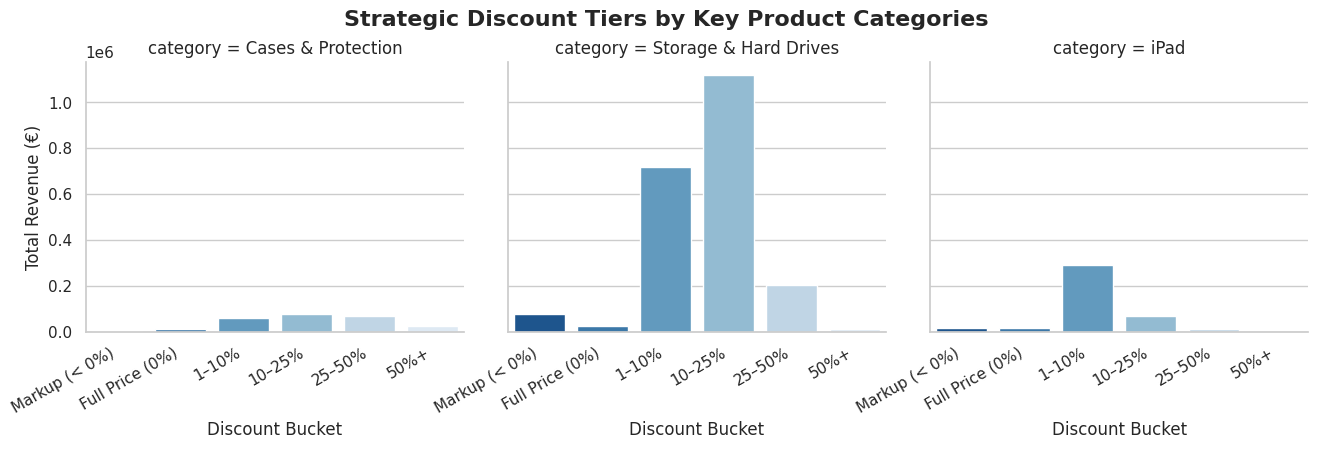

In [107]:
#Plot in Backup SLide
#FINAL PLOT - PRODUCT CATEGORIES & DISCOUNT BUCKETS

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Select only 3 strategic categories to keep the slide clean
key_categories = ['iPad', 'Storage & Hard Drives', 'Cases & Protection']
filtered_data = merged_datasets[
    merged_datasets['category'].isin(key_categories)
]

# 2. Group data by discount bucket and category
category_revenue = (
    filtered_data.groupby(['discount_bucket', 'category'])['unit_price_total']
    .sum()
    .reset_index()
)

# 3. Define the logical order for discount buckets
bucket_order = [
    'Markup (< 0%)',
    'Full Price (0%)',
    '1–10%',
    '10–25%',
    '25–50%',
    '50%+',
]

# 4. Create a clean 3-column catplot
sns.set_theme(style='whitegrid')

g = sns.catplot(
    data=category_revenue,
    x='discount_bucket',
    y='unit_price_total',
    col='category',  # Creates exactly 3 side-by-side panels
    kind='bar',
    order=bucket_order,
    height=4,
    aspect=1.1,
    palette='Blues_r',
)

# 5. Format labels and titles with larger font sizes for presentation readability
g.set_axis_labels(
    'Discount Bucket', 'Total Revenue (€)', fontsize=12
)  # Increases axis label size
g.set_xticklabels(
    rotation=30, ha='right', fontsize=11
)  # Rotates cleanly and sizes X ticks

# Explicitly size Y-axis tick values across all subplots so they remain visible
for ax in g.axes.flat:
  ax.tick_params(axis='y', labelsize=11)

g.fig.subplots_adjust(top=0.85)
g.fig.suptitle(
    'Strategic Discount Tiers by Key Product Categories',
    fontsize=16,
    fontweight='bold',
)

# SVG EXPORT
plt.savefig(
    'strategic_discount_tiers_by_category.svg',
    format='svg',
    bbox_inches='tight',
    transparent=True,
)


plt.show()

In [108]:
#Uncomment this when the .svg file needs to be downloaded on local system
#Importing & downloading the .svg file

#import os
#print([f for f in os.listdir() if f.endswith('.svg')])

#from google.colab import files
#files.download('strategic_discount_tiers_by_category.svg')

/tmp/ipykernel_3133/2592133319.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(
/tmp/ipykernel_3133/2592133319.py:52: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f'€{val*1e-6:.1f}M' for val in current_ticks], fontsize=10)


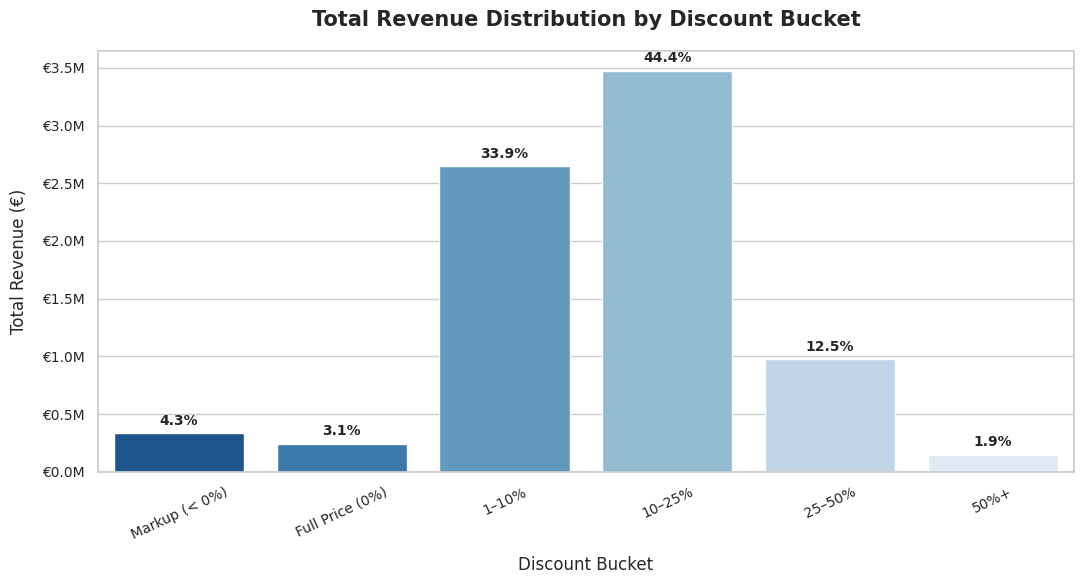

In [109]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Identify the revenue column name in your summary_revenue DataFrame
rev_col = (
    'unit_price_total'
    if 'unit_price_total' in summary_revenue.columns
    else 'total_revenue'
)

# 2. Calculate percentage share dynamically
total_sum = summary_revenue[rev_col].sum()
summary_revenue['revenue_share_pct'] = (
    summary_revenue[rev_col] / total_sum
) * 100

# 3. Define bucket order
bucket_order = [
    'Markup (< 0%)',
    'Full Price (0%)',
    '1–10%',
    '10–25%',
    '25–50%',
    '50%+',
]

# 4. Create bar plot using Seaborn
plt.figure(figsize=(11, 6))
sns.set_theme(style='whitegrid')

ax = sns.barplot(
    data=summary_revenue,
    x='discount_bucket',
    y=rev_col,
    order=bucket_order,
    palette='Blues_r',
)

# 5. Format labels and titles
plt.title(
    'Total Revenue Distribution by Discount Bucket',
    fontsize=15,
    fontweight='bold',
    pad=18,
)
plt.xlabel('Discount Bucket', fontsize=12, labelpad=10)
plt.ylabel('Total Revenue (€)', fontsize=12, labelpad=10)
plt.xticks(rotation=25, fontsize=10)

# 6. Format Y-axis in Millions (€M)
current_ticks = plt.yticks()[0]
ax.set_yticklabels([f'€{val*1e-6:.1f}M' for val in current_ticks], fontsize=10)

# 7. Map percentage labels to bar tops
pct_dict = dict(
    zip(
        summary_revenue['discount_bucket'],
        summary_revenue['revenue_share_pct'],
    )
)

for p, bucket in zip(ax.patches, bucket_order):
  height = p.get_height()
  if height > 0:
    pct_val = pct_dict.get(bucket, 0)
    ax.annotate(
        f'{pct_val:.1f}%',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        xytext=(0, 4),
        textcoords='offset points',
        fontsize=10,
        fontweight='semibold',
    )

plt.tight_layout()
plt.show()

<Figure size 1200x800 with 0 Axes>

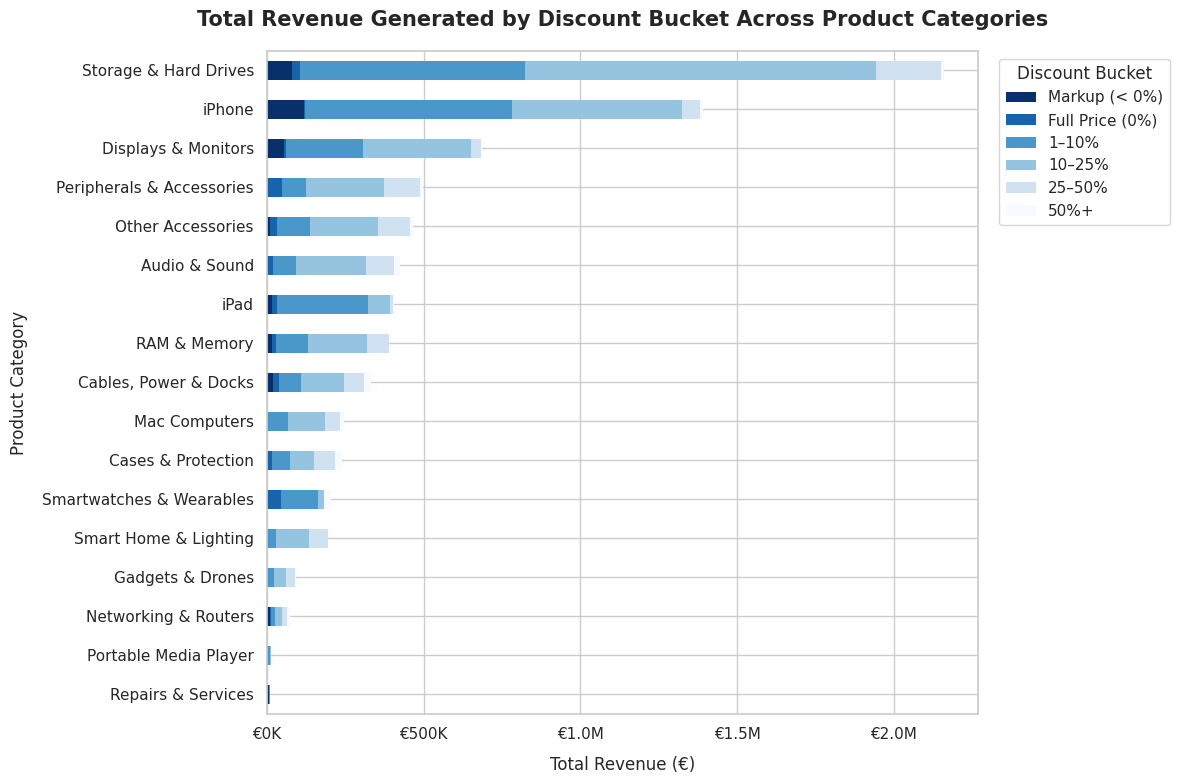

In [110]:
#Plot not in final presentation deck
#Plot for Total Revenue Generated by Discount Bucket Across Product Categories

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Define your canonical discount bucket order
bucket_order = [
    'Markup (< 0%)',
    'Full Price (0%)',
    '1–10%',
    '10–25%',
    '25–50%',
    '50%+',
]

# 2. Group data by category and discount bucket, summing total revenue
revenue_by_cat_bucket = (
    merged_datasets.groupby(['category', 'discount_bucket'])['unit_price_total']
    .sum()
    .unstack(fill_value=0)
)

# Reindex columns to ensure correct logical order and drop missing buckets if any
revenue_by_cat_bucket = revenue_by_cat_bucket.reindex(
    columns=bucket_order, fill_value=0
)

# 3. Sort categories by total revenue for a clean, hierarchical look
revenue_by_cat_bucket['Total'] = revenue_by_cat_bucket.sum(axis=1)
revenue_by_cat_bucket = revenue_by_cat_bucket.sort_values(
    by='Total', ascending=True
)
revenue_by_cat_bucket = revenue_by_cat_bucket.drop(columns=['Total'])

# 4. Set up the figure size and style
plt.figure(figsize=(12, 8))
sns.set_theme(style='whitegrid')

# 5. Create horizontal stacked bar chart using a polished blues palette
ax = revenue_by_cat_bucket.plot(
    kind='barh', stacked=True, figsize=(12, 8), colormap='Blues_r', edgecolor='none'
)

# 6. Formatting titles and labels
plt.title(
    'Total Revenue Generated by Discount Bucket Across Product Categories',
    fontsize=15,
    fontweight='bold',
    pad=18,
)
plt.xlabel('Total Revenue (€)', fontsize=12, labelpad=10)
plt.ylabel('Product Category', fontsize=12, labelpad=10)

# Format X-axis in Millions (€M)
from matplotlib.ticker import FuncFormatter

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'€{x*1e-6:.1f}M' if x >= 1e6 else f'€{x*1e-3:.0f}K')
)

# 7. Legend and layout
plt.legend(
    title='Discount Bucket',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    frameon=True,
)
plt.tight_layout()
plt.show()